# Lecture 13: GNNs and Mesh-Based Learning

We learn one time step of the 2D heat equation on unstructured triangular meshes with a graph neural network in the style of MeshGraphNets (Pfaff et al., ICLR 2021).

1. **Meshes and the exact solution**: random triangular meshes and a reference that does not depend on the mesh.
2. **A mesh as a graph**: edges, neighbors, edge lengths.
3. **How far message passing reaches**: the nodes within $K$ edges, on a coarse and fine mesh.
4. **The model**: encode, process, decode; a check of permutation equivariance.
5. **Edge geometry**: the same model with and without relative positions on the edges.
6. **Rollout on a new mesh**, with and without input noise during training.
7. **Finer meshes**: error against the number of nodes for $K$ = 2 and $K$ = 8 message-passing steps.

The models are trained checkpoints. No training in this notebook. The training code is at the end, for training offline. Message passing is written in plain PyTorch with `index_add_`, so no graph library.

In [1]:
import os
import urllib.request
from collections import deque
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from scipy.spatial import Delaunay
import torch
import torch.nn as nn

torch.manual_seed(0)
torch.set_num_threads(4)

DATA_DIR = "../data/lecture13"
URL = "https://raw.githubusercontent.com/eecs-ml4sci/eecs-ml4sci.github.io/main/data/lecture13/"
FILES = ["gnn_k8.pt", "gnn_k8_nogeom.pt", "gnn_k2.pt", "gnn_k8_noise.pt"]
os.makedirs(DATA_DIR, exist_ok=True)
for f in FILES:
    if not os.path.exists(os.path.join(DATA_DIR, f)):
        print("downloading", f)
        urllib.request.urlretrieve(URL + f, os.path.join(DATA_DIR, f))

---
## Part 1: Meshes and the exact solution

Heat equation on the unit square with zero temperature on the boundary:

$$u_t = \alpha\,(u_{xx} + u_{yy}), \qquad u = 0 \text{ on the boundary}, \qquad \alpha = 1 .$$

An initial condition $u_0(x, y) = \sum_{m,n=1}^{10} a_{mn} \sin(m\pi x)\sin(n\pi y)$ has the exact solution

$$u(x, y, t) = \sum_{m,n} a_{mn}\, e^{-\alpha\pi^2 (m^2 + n^2) t} \sin(m\pi x)\sin(n\pi y).$$

Each mode decays independently. We draw $a_{mn} \sim \mathcal N(0, 1)/(m^2 + n^2)^{2.5}$. Because the solution is known everywhere, we can evaluate it at the nodes of any mesh, and the reference does not depend on the mesh.

The model learns one step of $\Delta t = 2\times10^{-3}$: $u(\cdot, t) \mapsto u(\cdot, t + \Delta t)$.

**Meshes.** A jittered $n \times n$ point set, warped by $x \mapsto x - w\sin(2\pi x)/(2\pi)$ in each direction ($w < 0$ adds more nodes near the centre, $w > 0$ near the walls), then triangulated with Delaunay.

In [2]:
ALPHA, DT, MMAX = 1.0, 2e-3, 10

def make_mesh(n_side, warp=0.0, seed=0, jitter=0.3):
    # triangular mesh of the unit square; returns positions [N, 2], triangles [T, 3], boundary mask [N]
    rng = np.random.default_rng(seed)
    s = np.linspace(0, 1, n_side); h = 1.0 / (n_side - 1)
    X, Y = np.meshgrid(s, s, indexing="ij")
    X = X + rng.uniform(-jitter, jitter, X.shape) * h
    Y = Y + rng.uniform(-jitter, jitter, Y.shape) * h
    X[0, :], X[-1, :], Y[:, 0], Y[:, -1] = 0, 1, 0, 1
    X, Y = np.clip(X, 0, 1), np.clip(Y, 0, 1)
    wx, wy = warp if np.ndim(warp) else (warp, warp)
    X = X - wx * np.sin(2 * np.pi * X) / (2 * np.pi)
    Y = Y - wy * np.sin(2 * np.pi * Y) / (2 * np.pi)
    pos = np.stack([X.ravel(), Y.ravel()], 1)
    tri = Delaunay(pos).simplices
    a = pos[tri]
    area = 0.5 * np.abs((a[:, 1, 0] - a[:, 0, 0]) * (a[:, 2, 1] - a[:, 0, 1]) - (a[:, 2, 0] - a[:, 0, 0]) * (a[:, 1, 1] - a[:, 0, 1]))
    tri = tri[area > 1e-3 * h * h]                       # drop slivers on the boundary
    bnd = (pos[:, 0] < 1e-9) | (pos[:, 0] > 1 - 1e-9) | (pos[:, 1] < 1e-9) | (pos[:, 1] > 1 - 1e-9)
    return pos.astype(np.float32), tri, bnd

def random_coeffs(B, power=2.5, seed=0):
    rng = np.random.default_rng(seed)
    m = np.arange(1, MMAX + 1); k2 = m[:, None] ** 2 + m[None, :] ** 2
    return rng.standard_normal((B, MMAX, MMAX)) / k2 ** power

def heat_eval(coef, pos, t):
    # exact solution at points pos [N, 2] and time t (scalar or [B]); coef [B, M, M] -> [B, N]
    m = np.arange(1, MMAX + 1); k2 = m[:, None] ** 2 + m[None, :] ** 2
    t = np.broadcast_to(np.asarray(t, float), (coef.shape[0],))
    c = coef * np.exp(-ALPHA * np.pi ** 2 * k2[None] * t[:, None, None])
    Sx, Sy = np.sin(np.pi * pos[:, 0:1] * m[None]), np.sin(np.pi * pos[:, 1:2] * m[None])
    return np.einsum("bmn,im,in->bi", c, Sx, Sy)

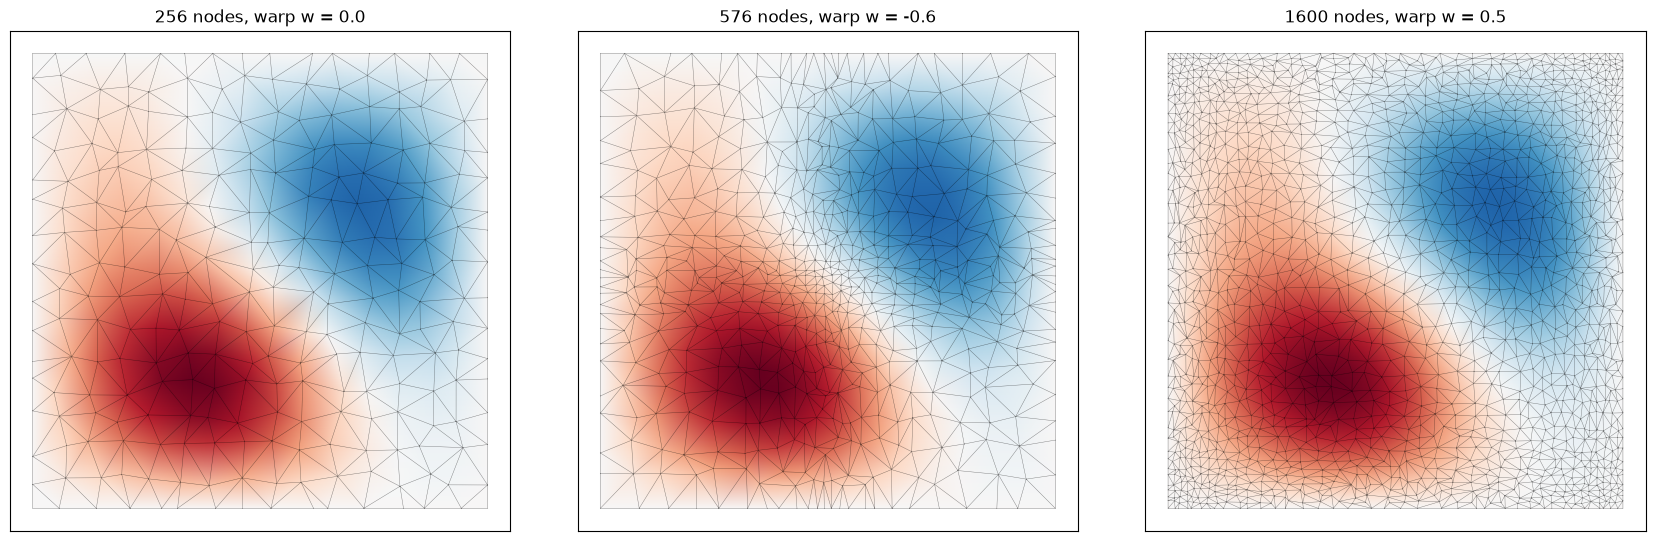

In [3]:
coef = random_coeffs(1, seed=11)
fig, ax = plt.subplots(1, 3, figsize=(17, 5.3), layout="constrained")
for a, (n, w) in zip(ax, [(16, 0.0), (24, -0.6), (40, 0.5)]):
    pos, tri, bnd = make_mesh(n, warp=w, seed=3)
    u = heat_eval(coef, pos, 0.0)[0]
    v = np.abs(u).max()
    a.tripcolor(pos[:, 0], pos[:, 1], tri, u, shading="gouraud", cmap="RdBu_r", vmin=-v, vmax=v)
    a.triplot(pos[:, 0], pos[:, 1], tri, color="k", lw=0.3, alpha=0.5)
    a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])
    a.set_title(f"{len(pos)} nodes, warp w = {w}")
plt.show()

**What to observe**

* The three meshes cover the same square with 256 to 1600 nodes. With $w = -0.6$ the nodes cluster near the centre; with $w = 0.5$ they cluster near the walls.
* The field is the same function on all three meshes, only the sample points change.
* With coefficients that fall off like $(m^2 + n^2)^{-2.5}$, the solution is smooth: modes above about 4 carry little energy, so the above meshes resolves it.

---
## Part 2: A mesh as a graph

Every side of a triangle becomes two directed edges, $j \to i$ and $i \to j$. The edge $j \to i$ carries the relative position $\mathbf x_i - \mathbf x_j$ and its length. Node $i$'s neighbors $\mathcal N(i)$ are the senders of its incoming edges.

256 nodes, w = 0.0: 1410 directed edges, mean degree 5.99, edge length 0.031 to 0.122
576 nodes, w = -0.6: 3266 directed edges, mean degree 6.03, edge length 0.010 to 0.106
1600 nodes, w = 0.5: 9282 directed edges, mean degree 5.98, edge length 0.006 to 0.068


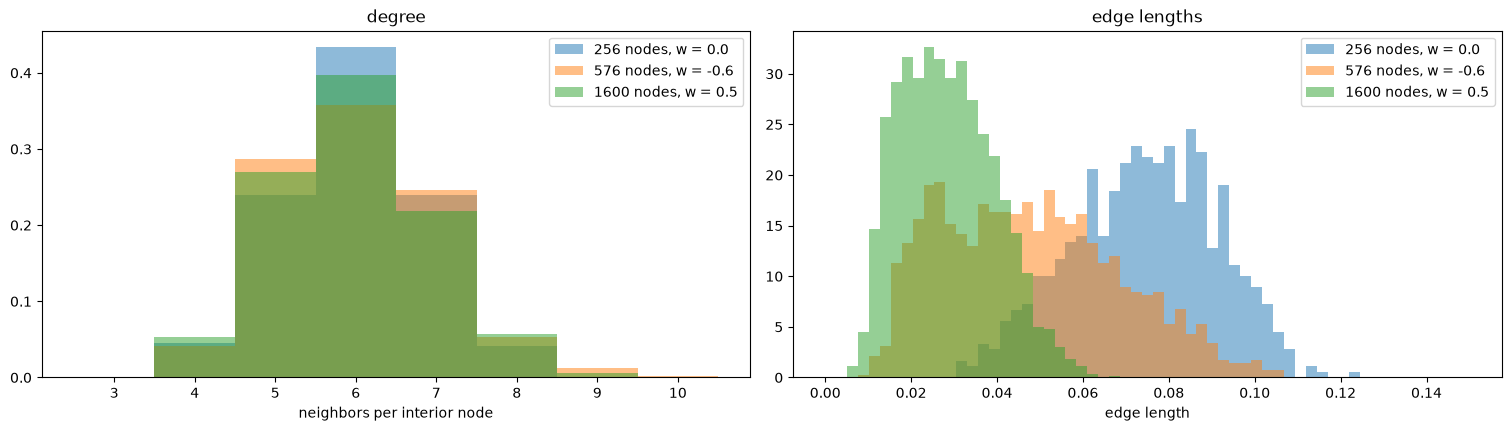

In [4]:
def edges_from_triangles(tri):
    # directed edges of a triangle mesh: senders, receivers (each undirected edge in both directions)
    e = np.concatenate([tri[:, [0, 1]], tri[:, [1, 2]], tri[:, [2, 0]]])
    e = np.unique(np.sort(e, 1), axis=0)
    return np.concatenate([e[:, 0], e[:, 1]]), np.concatenate([e[:, 1], e[:, 0]])

fig, ax = plt.subplots(1, 2, figsize=(15, 4.2), layout="constrained")
for n, w, col in [(16, 0.0, "C0"), (24, -0.6, "C1"), (40, 0.5, "C2")]:
    pos, tri, bnd = make_mesh(n, warp=w, seed=3)
    snd, rcv = edges_from_triangles(tri)
    deg = np.bincount(rcv, minlength=len(pos))[~bnd]
    length = np.linalg.norm(pos[rcv] - pos[snd], axis=1)
    lab = f"{len(pos)} nodes, w = {w}"
    ax[0].hist(deg, bins=np.arange(2.5, 11.5), alpha=0.5, color=col, label=lab, density=True)
    ax[1].hist(length, bins=np.linspace(0, 0.15, 60), alpha=0.5, color=col, label=lab, density=True)
    print(f"{lab}: {len(snd)} directed edges, mean degree {deg.mean():.2f}, edge length {length.min():.3f} to {length.max():.3f}")
ax[0].set(xlabel="neighbors per interior node", title="degree"); ax[0].legend()
ax[1].set(xlabel="edge length", title="edge lengths"); ax[1].legend()
plt.show()

**What to observe**

* Interior nodes have about 6 neighbors on every mesh. The degree does not change with resolution or warping.
* Edge lengths change a lot: 0.03 to 0.12 on the 256-node mesh, 0.006 to 0.07 on the 1600-node mesh. A model whose messages depend on edge length sees new inputs on a much finer mesh.
* A warped mesh has a wide spread of edge lengths within one mesh.

---
## Part 3: How far message passing reaches

One message-passing step moves information along one edge. We count, for a node near the centre, how many edges separate it from every other node (breadth-first search), and convert that to physical distance.

In one step $\Delta t$, diffusion spreads over a distance of about $\sqrt{2\alpha\Delta t}$ (the standard deviation of the heat kernel). The model must see at least that far, with some margin, since the kernel has tails.

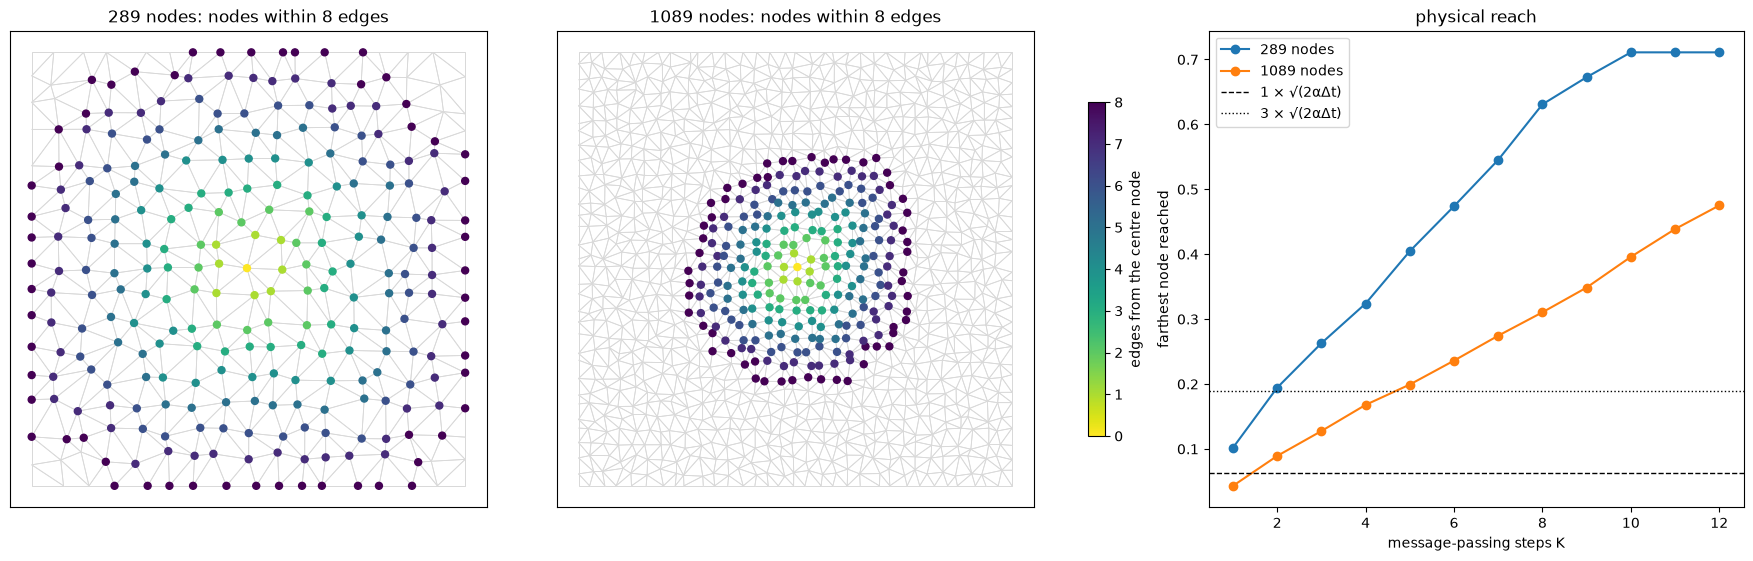

In [5]:
def hops_from(node, snd, rcv, N):
    adj = [[] for _ in range(N)]
    for a, b in zip(snd, rcv):
        adj[a].append(b)
    hop = np.full(N, -1); hop[node] = 0; q = deque([node])
    while q:
        a = q.popleft()
        for b in adj[a]:
            if hop[b] < 0:
                hop[b] = hop[a] + 1; q.append(b)
    return hop

fig, ax = plt.subplots(1, 3, figsize=(18, 5.5), layout="constrained")
for a, n in zip(ax[:2], (17, 33)):
    pos, tri, bnd = make_mesh(n, seed=7)
    snd, rcv = edges_from_triangles(tri)
    c = int(np.argmin(np.linalg.norm(pos - 0.5, axis=1)))
    hop = hops_from(c, snd, rcv, len(pos))
    a.add_collection(LineCollection(np.stack([pos[snd], pos[rcv]], 1), colors="0.85", lw=0.6))
    sc = a.scatter(*pos[hop <= 8].T, c=hop[hop <= 8], cmap="viridis_r", s=25, vmin=0, vmax=8, zorder=2)
    a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([]); a.set_title(f"{n * n} nodes: nodes within 8 edges")
    reach = [np.linalg.norm(pos[hop <= K] - pos[c], axis=1).max() for K in range(1, 13)]
    ax[2].plot(range(1, 13), reach, "o-", label=f"{n * n} nodes")
fig.colorbar(sc, ax=ax[:2], shrink=0.7, label="edges from the centre node")
L = np.sqrt(2 * ALPHA * DT)
for f, ls in [(1, "--"), (3, ":")]:
    ax[2].axhline(f * L, color="k", ls=ls, lw=1, label=f"{f} × √(2αΔt)")
ax[2].set(xlabel="message-passing steps K", ylabel="farthest node reached", title="physical reach"); ax[2].legend()
plt.show()

**What to observe**

* The reach grows about linearly with $K$, at a rate set by the edge length. After 8 steps the node on the fine mesh reaches about half as far as on the coarse mesh.
* The diffusion length $\sqrt{2\alpha\Delta t} \approx 0.063$ (dashed) takes 1 to 2 steps on the coarse mesh and 2 on the fine mesh. Three times that (dotted) takes 2 steps on the coarse mesh and about 5 on the fine mesh.
* So $K = 8$ covers the heat kernel's tails on the training meshes, and $K = 2$ does not.

---
## Part 4: The model

Encode, process, decode, as in MeshGraphNets:

* **Encoder.** Node input: $u_i$ and a boundary flag. Edge input: $\mathbf x_i - \mathbf x_j$, its length, and $u_j - u_i$. Each is mapped by an MLP to 64 numbers.
* **Processor.** $K$ message-passing steps, each with its own weights:
$$\mathbf e_{ij} \leftarrow \mathbf e_{ij} + \phi_e(\mathbf e_{ij}, \mathbf h_i, \mathbf h_j), \qquad \mathbf h_i \leftarrow \mathbf h_i + \phi_h\Big(\mathbf h_i, \sum_{j \in \mathcal N(i)} \mathbf e_{ij}\Big).$$
* **Decoder.** An MLP returns the standardized increment $\big(u_i(t + \Delta t) - u_i(t)\big)/\sigma$ at each node. Boundary nodes are reset to 0 after the step.

Four trained models, all with width 64 and the same training data:

| file | $K$ | edge input |
|---|---|---|
| `gnn_k8.pt` | 8 | relative position, length, $u_j - u_i$ |
| `gnn_k8_nogeom.pt` | 8 | a constant in place of the relative position and length; $u_j - u_i$ |
| `gnn_k2.pt` | 2 | relative position, length, $u_j - u_i$ |
| `gnn_k8_noise.pt` | 8 | as `gnn_k8`, then fine-tuned with input noise |

Training: 200 meshes with 400 to 1024 nodes and random warps $w \in [-0.6, 0.6]$; initial conditions at a random time $t \in [0, 0.05]$, scaled to unit RMS (the equation is linear, so this changes nothing physically). MSE loss on interior nodes, Adam (lr $10^{-3}$, cosine schedule), 4 meshes per batch, 6000 steps for `gnn_k8` and 4000 for `gnn_k8_nogeom` and `gnn_k2`. `gnn_k8_noise` starts from `gnn_k8` and trains 2,500 more steps (lr $3\times10^{-4}$) with Gaussian noise of standard deviation 0.005 added to the input $u$ at interior nodes; the target becomes $u(t+\Delta t) - (u + \text{noise})$, so the model learns to undo the noise (GNS, Sanchez-Gonzalez et al. 2020).

Because the equation is linear, `step` scales each input to unit RMS, applies the network, and scales the output back.

In [6]:
EDGE_SCALE = 30.0   # relative positions are multiplied by this (about 1 / typical edge length)

class Graph:
    def __init__(self, pos, tri, bnd):
        self.pos, self.tri, self.bnd = pos, tri, bnd
        s, r = edges_from_triangles(tri)
        self.senders, self.receivers = torch.as_tensor(s), torch.as_tensor(r)
        d = pos[r] - pos[s]                                         # x_i - x_j on edge j -> i
        self.edge_feat = torch.as_tensor(np.concatenate([d, np.linalg.norm(d, axis=1, keepdims=True)], 1) * EDGE_SCALE, dtype=torch.float32)
        self.node_type = torch.as_tensor(bnd, dtype=torch.float32)[:, None]
        self.N = len(pos)

def mlp(i, h, o, norm=True):
    layers = [nn.Linear(i, h), nn.SiLU(), nn.Linear(h, h), nn.SiLU(), nn.Linear(h, o)]
    return nn.Sequential(*layers, nn.LayerNorm(o)) if norm else nn.Sequential(*layers)

class MeshGNN(nn.Module):
    def __init__(self, K=8, width=64, use_geometry=True):
        super().__init__()
        self.K, self.use_geometry = K, use_geometry
        self.node_enc, self.edge_enc = mlp(2, width, width), mlp(4, width, width)
        self.edge_mlps = nn.ModuleList([mlp(3 * width, width, width) for _ in range(K)])
        self.node_mlps = nn.ModuleList([mlp(2 * width, width, width) for _ in range(K)])
        self.dec = mlp(width, width, 1, norm=False)
        for b in ("in_std", "out_std", "diff_std"):
            self.register_buffer(b, torch.tensor(1.0))

    def forward(self, u, senders, receivers, edge_feat, node_type):
        h = self.node_enc(torch.cat([u[:, None] / self.in_std, node_type], 1))
        geo = edge_feat if self.use_geometry else torch.ones_like(edge_feat)
        du_edge = (u[senders] - u[receivers])[:, None] / self.diff_std
        e = self.edge_enc(torch.cat([geo, du_edge], 1))
        for k in range(self.K):
            e = e + self.edge_mlps[k](torch.cat([e, h[receivers], h[senders]], 1))   # message on every edge j -> i
            agg = torch.zeros_like(h).index_add_(0, receivers, e)                    # sum over incoming edges
            h = h + self.node_mlps[k](torch.cat([h, agg], 1))
        return self.dec(h)[:, 0]

    def step(self, u, g):
        # one time step on graph g: u [N] -> u [N]; boundary nodes set to 0
        sc = u.pow(2).mean().sqrt().clamp_min(1e-12)       # linear equation: work at unit RMS, scale back
        du = self(u / sc, g.senders, g.receivers, g.edge_feat, g.node_type) * self.out_std * sc
        return torch.where(torch.as_tensor(g.bnd), torch.zeros_like(u), u + du)

def load(name):
    ck = torch.load(os.path.join(DATA_DIR, name + ".pt"))
    m = MeshGNN(K=ck["K"], use_geometry=ck["use_geometry"]); m.load_state_dict(ck["state"]); m.eval()
    return m

models = {n: load(n) for n in ["gnn_k8", "gnn_k8_nogeom", "gnn_k2", "gnn_k8_noise"]}
for n, m in models.items():
    print(f"{n:15s} {sum(p.numel() for p in m.parameters()):,} parameters")

gnn_k8          325,825 parameters
gnn_k8_nogeom   325,825 parameters
gnn_k2          100,801 parameters
gnn_k8_noise    325,825 parameters


**Permutation equivariance.** We renumber the nodes with a random permutation, apply the model, and undo the permutation. The result should equal the prediction on the original numbering, up to round-off.

In [7]:
pos, tri, bnd = make_mesh(24, warp=(-0.4, 0.3), seed=123)
g = Graph(pos, tri, bnd)
u = torch.as_tensor(heat_eval(random_coeffs(1, seed=5), pos, 0.0)[0], dtype=torch.float32)

perm = np.random.default_rng(0).permutation(len(pos))      # new node k is old node perm[k]
inv = np.argsort(perm)
gp = Graph(pos[perm], inv[tri], bnd[perm])                  # same mesh, renumbered
with torch.no_grad():
    out = models["gnn_k8"].step(u, g)
    out_p = models["gnn_k8"].step(u[perm], gp)
print("max |f(Pu) - P f(u)| =", float((out_p - out[perm]).abs().max()))

max |f(Pu) - P f(u)| = 1.4901161193847656e-08


**What to observe**

* The renumbered prediction matches to float32 round-off. The model is permutation equivariant by construction.
* `gnn_k2` has fewer parameters because it has fewer processor steps. The other three models have the same architecture.

---
## Part 5: Edge geometry

We compare the model with relative positions on the edges to the one without, on new meshes: uniform ($w = 0$) and warped. The error is the relative $L^2$ error of the predicted increment at interior nodes,

$$\frac{\| \hat u(t + \Delta t) - u(t + \Delta t) \|}{\| u(t + \Delta t) - u(t) \|},$$

so predicting no change ($\hat u = u(t)$) gives an error of 1.

gnn_k8          uniform: 0.1010   warped: 0.1043
gnn_k8_nogeom   uniform: 0.2035   warped: 0.2027


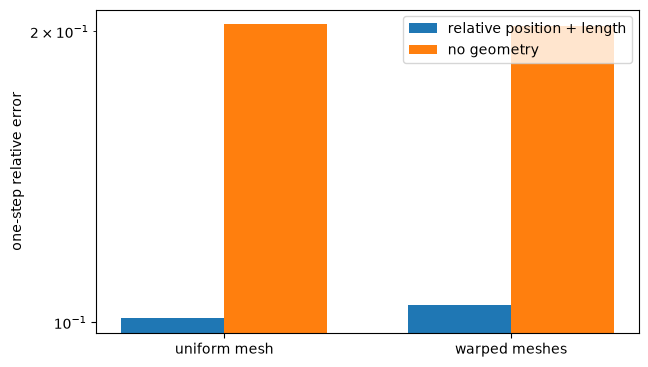

In [8]:
@torch.no_grad()
def onestep_error(model, n_side, warp=0.6, n_mesh=6, n_samp=8, seed=0):
    rng = np.random.default_rng(seed); errs = []
    for k in range(n_mesh):
        g = Graph(*make_mesh(n_side, warp=rng.uniform(-warp, warp, 2), seed=9000 + 100 * n_side + k))
        c = random_coeffs(n_samp, seed=7000 + k); t = rng.uniform(0, 0.05, n_samp)
        u0, u1 = heat_eval(c, g.pos, t), heat_eval(c, g.pos, t + DT)
        inner = ~g.bnd
        for b in range(n_samp):
            p = model.step(torch.as_tensor(u0[b], dtype=torch.float32), g).numpy()
            errs.append(np.linalg.norm((p - u1[b])[inner]) / np.linalg.norm((u1[b] - u0[b])[inner]))
    return np.mean(errs)

rows = []
for name in ["gnn_k8", "gnn_k8_nogeom"]:
    rows.append([onestep_error(models[name], 24, warp=0.0), onestep_error(models[name], 24, warp=0.6)])
    print(f"{name:15s} uniform: {rows[-1][0]:.4f}   warped: {rows[-1][1]:.4f}")

fig, ax = plt.subplots(figsize=(7, 4.2))
xb = np.arange(2)
ax.bar(xb - 0.18, rows[0], 0.36, label="relative position + length")
ax.bar(xb + 0.18, rows[1], 0.36, label="no geometry")
ax.set_xticks(xb); ax.set_xticklabels(["uniform mesh", "warped meshes"])
ax.set_ylabel("one-step relative error"); ax.set_yscale("log"); ax.legend(); plt.show()

**What to observe**

* Without edge geometry the one-step error is clearly higher, on the uniform mesh and on the warped meshes.
* Even the uniform mesh is jittered, so neighbors sit at different distances. The model without geometry sees $u_j - u_i$ but cannot weight a neighbor by its distance or direction.
* Both errors are well below 1, so both models learned most of the step.

---
## Part 6: Rollout on a new mesh

We start from an exact initial condition and apply the model 25 times, each time to its own output.

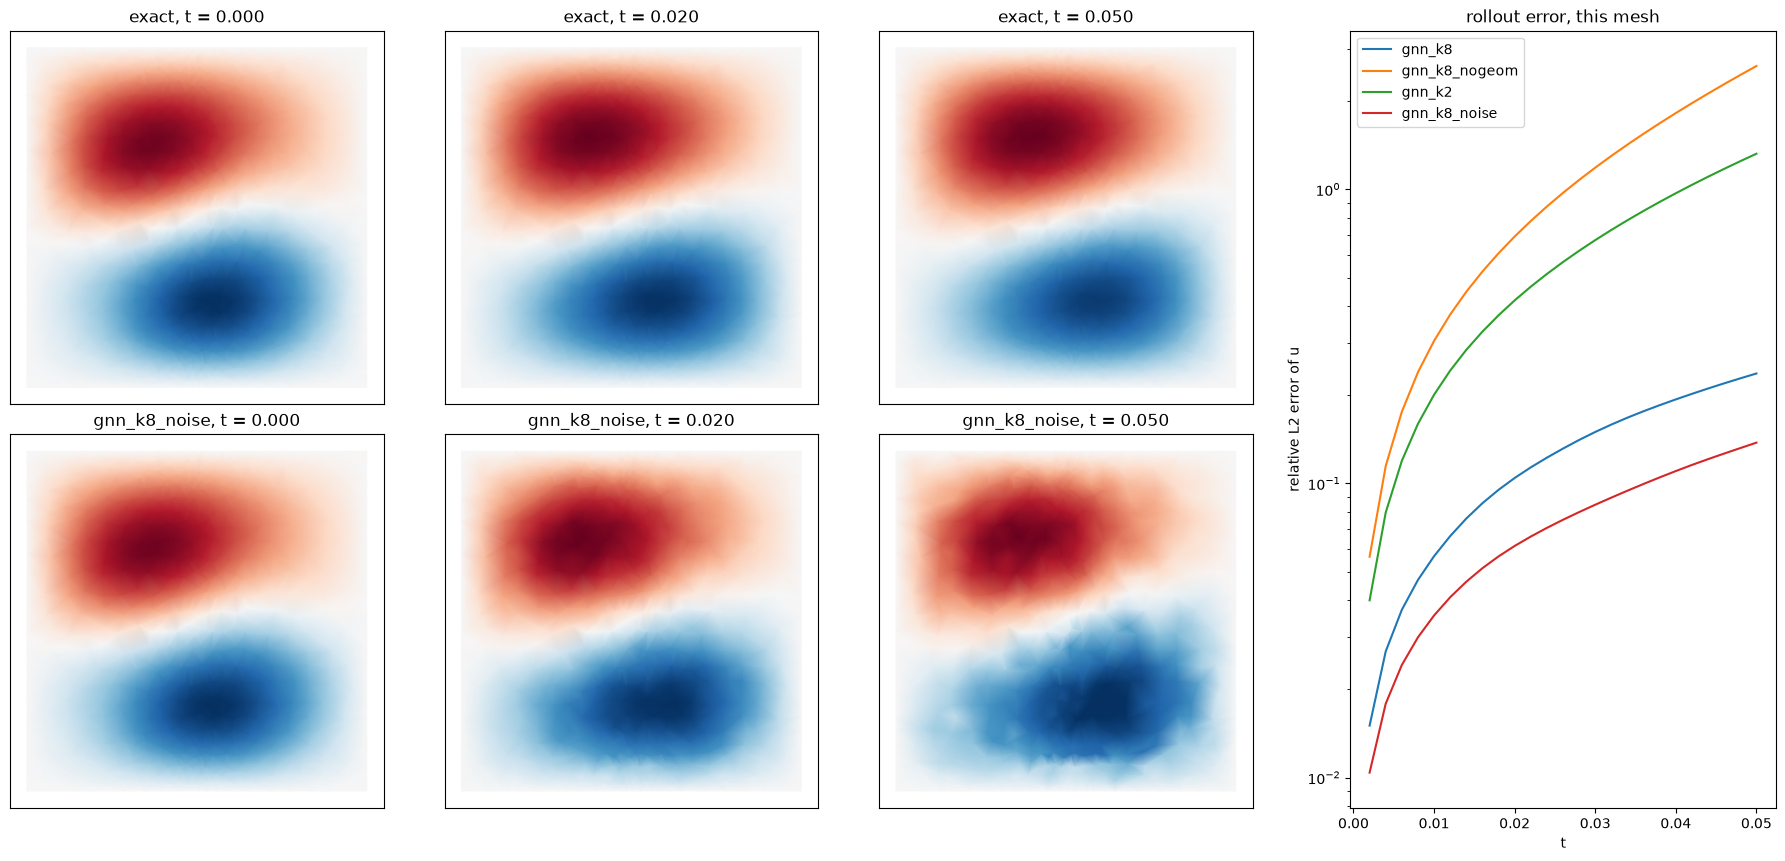

In [9]:
@torch.no_grad()
def rollout(model, g, u0, steps=25):
    u = torch.as_tensor(u0, dtype=torch.float32); out = [u.numpy()]
    for _ in range(steps):
        u = model.step(u, g); out.append(u.numpy())
    return np.stack(out)

g = Graph(*make_mesh(26, warp=(-0.5, 0.4), seed=4242))
c = random_coeffs(1, seed=4411)              # an initial condition with little energy in the lowest mode
ts = DT * np.arange(26)
truth = np.stack([heat_eval(c, g.pos, t)[0] for t in ts])
pred = {n: rollout(m, g, truth[0]) for n, m in models.items()}

fig, ax = plt.subplots(2, 4, figsize=(18, 8.5), layout="constrained")
for col, j in enumerate([0, 10, 25]):
    for row, (lab, f) in enumerate([("exact", truth[j]), ("gnn_k8_noise", pred["gnn_k8_noise"][j])]):
        a = ax[row, col]
        v = np.abs(truth[j]).max()                                 # color scale follows the decaying solution
        a.tripcolor(g.pos[:, 0], g.pos[:, 1], g.tri, f, shading="gouraud", cmap="RdBu_r", vmin=-v, vmax=v)
        a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([]); a.set_title(f"{lab}, t = {ts[j]:.3f}")
gs = ax[0, 3].get_gridspec(); ax[0, 3].remove(); ax[1, 3].remove()
a = fig.add_subplot(gs[:, 3])
for n in models:
    e = np.linalg.norm(pred[n] - truth, axis=1) / np.linalg.norm(truth, axis=1)
    a.plot(ts[1:], e[1:], label=n)
a.set(xlabel="t", ylabel="relative L2 error of u", yscale="log", title="rollout error, this mesh"); a.legend()
plt.show()

One mesh can mislead. We repeat the rollout on 5 new meshes with 3 initial conditions each and report the median error after 5, 10 and 25 steps.

In [10]:
rng = np.random.default_rng(3); E = {n: [] for n in models}
for k in range(5):
    gg = Graph(*make_mesh(int(rng.integers(22, 30)), warp=rng.uniform(-0.6, 0.6, 2), seed=5000 + k))
    for b in range(3):
        cc = random_coeffs(1, seed=600 + 10 * k + b)
        tr = np.stack([heat_eval(cc, gg.pos, DT * s)[0] for s in range(26)])
        for n, m in models.items():
            out = rollout(m, gg, tr[0])
            E[n].append(np.linalg.norm(out - tr, axis=1) / np.linalg.norm(tr, axis=1))
for n in E:
    med = np.median(np.array(E[n]), 0)
    print(f"{n:15s} median error after 5, 10, 25 steps: {med[5]:.4f}  {med[10]:.4f}  {med[25]:.4f}")

gnn_k8          median error after 5, 10, 25 steps: 0.0238  0.0401  0.3204
gnn_k8_nogeom   median error after 5, 10, 25 steps: 0.0486  0.0769  0.1234
gnn_k2          median error after 5, 10, 25 steps: 0.0416  0.0632  0.0864
gnn_k8_noise    median error after 5, 10, 25 steps: 0.0167  0.0259  0.0428


**What to observe**

* On this mesh, `gnn_k8_nogeom` and `gnn_k2` drift far from the exact solution: after 25 steps their errors are larger than the solution itself. `gnn_k8` grows more slowly, and `gnn_k8_noise` has the lowest error throughout.
* Over the 15 rollouts, `gnn_k8` has the lowest error of the three models trained without noise after 5 and 10 steps, but the highest after 25 steps: its error grows fastest late in the rollout. One-step accuracy does not decide rollout accuracy.
* `gnn_k8_noise` has the lowest median error at every horizon. Training on noisy inputs teaches the model to correct inputs like its own slightly wrong outputs.

---
## Part 7: Finer meshes

All models were trained on meshes with 400 to 1024 nodes. We evaluate them on new meshes from 256 to 4096 nodes.

gnn_k8 [0.1192 0.1151 0.1043 0.1119 0.1197 0.1417 0.1742 0.3256]
gnn_k2 [0.1969 0.1882 0.1854 0.1867 0.1925 0.2201 0.2732 0.4459]
gnn_k8_nogeom [0.3197 0.2277 0.2027 0.1997 0.2007 0.2045 0.2066 0.2082]


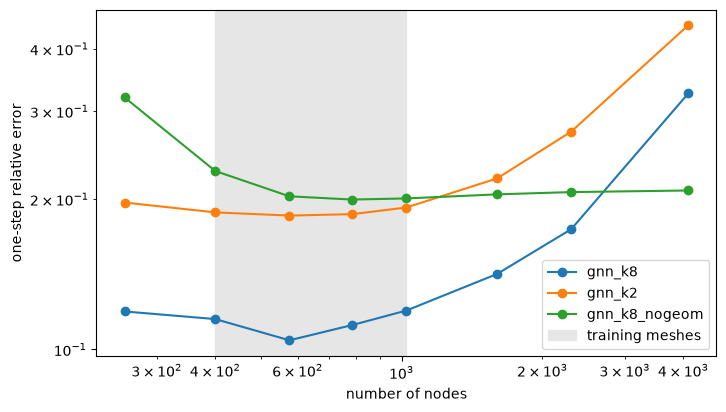

In [11]:
n_sides = [16, 20, 24, 28, 32, 40, 48, 64]
fig, ax = plt.subplots(figsize=(8, 4.5))
for name in ["gnn_k8", "gnn_k2", "gnn_k8_nogeom"]:
    e = [onestep_error(models[name], n) for n in n_sides]
    ax.plot(np.square(n_sides), e, "o-", label=name)
    print(name, np.round(e, 4))
ax.axvspan(400, 1024, color="0.9", label="training meshes")
ax.set(xscale="log", yscale="log", xlabel="number of nodes", ylabel="one-step relative error"); ax.legend()
plt.show()

**What to observe**

* `gnn_k8` has its lowest error on meshes with 576 to 1024 nodes, inside the training range. On finer meshes the error grows, to about three times as high at 4096 nodes.
* `gnn_k2` is higher at every size: 2 steps do not reach far enough even on the training meshes. It also grows on finer meshes.
* `gnn_k8_nogeom` is about flat from 576 to 4096 nodes and higher than `gnn_k8` everywhere except the finest mesh. It never sees edge lengths, so a finer mesh gives it no unfamiliar inputs, but it is less accurate on the meshes it was trained for.

---
## Exercises

1. **Rotation.** The square and the boundary condition are unchanged by a 90° rotation. Rotate the mesh positions by 90° about $(0.5, 0.5)$ (keep the field values at the nodes), apply `gnn_k8`, and compare with the prediction on the original mesh. Is the model rotation-equivariant? Which input breaks it? How does EGNN (slide 20) avoid this?
2. **Mean instead of sum.** Change the aggregation in `forward` to a mean over incoming edges (divide `agg` by the degree) and train a model with the code below. Compare the errors on the finest meshes in Part 7. Which aggregation does the graph kernel network use, and why?
3. **More steps for finer meshes.** Train $K = 16$ on the same meshes and repeat Part 7. Then train $K = 8$ on meshes with 1600 to 2500 nodes. Which helps more on 4096-node meshes?
4. **Noise level.** Fine-tune `gnn_k8` with input noise of standard deviation 0.001, 0.005 and 0.02 (`train_gnn(..., noise=σ, init=models["gnn_k8"])`). Plot the one-step error and the median rollout error after 25 steps against σ. Is there a trade-off?


In [12]:
# Training code (used for the checkpoints; run offline, e.g. on one HPC3 GPU)
def batch_graphs(graphs):
    off, S, Rv, E, NT = 0, [], [], [], []
    for g in graphs:
        S.append(g.senders + off); Rv.append(g.receivers + off); E.append(g.edge_feat); NT.append(g.node_type); off += g.N
    return torch.cat(S), torch.cat(Rv), torch.cat(E), torch.cat(NT)

def train_gnn(K=8, use_geometry=True, steps=6000, n_meshes=200, seed=1, noise=0.0, init=None, lr=1e-3):
    rng = np.random.default_rng(seed)
    meshes = [Graph(*make_mesh(int(rng.integers(20, 33)), warp=rng.uniform(-0.6, 0.6, 2), seed=1000 + i)) for i in range(n_meshes)]
    def sample(g, s):
        c = random_coeffs(1, seed=s); t = rng.uniform(0, 0.05)
        u0, u1 = heat_eval(c, g.pos, t)[0], heat_eval(c, g.pos, t + DT)[0]
        sc = 1 / np.sqrt((u0 ** 2).mean()); return u0 * sc, u1 * sc
    if init is not None:                                   # fine-tune a trained model (keeps its normalization)
        model = MeshGNN(K=init.K, use_geometry=init.use_geometry); model.load_state_dict(init.state_dict())
    else:
        model = MeshGNN(K=K, use_geometry=use_geometry)
        a = [sample(meshes[i], 50_000 + i) for i in range(40)]
        model.in_std.fill_(float(np.std([x[0] for x in a])))
        model.out_std.fill_(float(np.std(np.concatenate([x[1] - x[0] for x in a]))))
        model.diff_std.fill_(float(np.std(np.concatenate([x[0][meshes[i].senders] - x[0][meshes[i].receivers] for i, x in enumerate(a)]))))
    model.train()
    opt = torch.optim.Adam(model.parameters(), lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps, eta_min=1e-5)
    for it in range(steps):
        gs = [meshes[j] for j in rng.integers(0, n_meshes, 4)]
        pairs = [sample(g, it * 10 + j) for j, g in enumerate(gs)]
        # GNS-style input noise on interior nodes; the target asks the model to undo it
        pairs = [(p[0] + rng.normal(0, noise, p[0].shape) * (~g.bnd), p[1]) for p, g in zip(pairs, gs)]
        u0 = torch.as_tensor(np.concatenate([p[0] for p in pairs]), dtype=torch.float32)
        du = torch.as_tensor(np.concatenate([p[1] - p[0] for p in pairs]), dtype=torch.float32)
        S, Rv, E, NT = batch_graphs(gs)
        pred = model(u0, S, Rv, E, NT); inner = NT[:, 0] == 0
        loss = ((pred - du / model.out_std)[inner] ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    return model

# model = train_gnn(K=8)
# noisy = train_gnn(steps=2500, noise=0.005, init=models["gnn_k8"], lr=3e-4)
# torch.save({"K": model.K, "use_geometry": model.use_geometry, "state": model.state_dict()}, "my_gnn.pt")